# RF Pulse Design

**Part:** E – RF pulses and excitation · **Reading time:** ~90 min · **Pass 1 overview:** [From signal to image](../pass1_big_picture/P1.3_From_Signal_to_Image.ipynb) · **Refreshers you may want:** [complex numbers & rotations](../refreshers/RM2_Complex_Numbers_and_Rotations.ipynb), [continuous FT vs DFT](../refreshers/RM3_Continuous_FT_and_DFT.ipynb), [Fourier properties](../refreshers/RM4_Fourier_Properties.ipynb), [Fourier pairs & windowing](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)

RF pulse design in the small-tip regime (up to roughly 30–60°) can use the Fourier transform, while larger flip-angle designs such as 90° and 180° pulses benefit from advanced techniques like the **Shinnar–Le Roux (SLR)** algorithm.

**Why this chapter matters.** The two previous chapters showed *what* a pulse does. Here you learn *how to build* one to a specification: a target flip angle, slice thickness, sharpness (transition width), ripple, duration and peak power. We go from the classic windowed sinc to the SLR algorithm – which turns pulse design into ordinary digital FIR filter design, the kind you know from DSP – and briefly to adiabatic and multi-band pulses used in modern sequences.

## Learning goals

1. Manipulate MRI sequence parameters to improve performance
    * Understand how to design RF pulses
2. *(added)* Design a windowed-sinc pulse from specifications (θ, $T_{rf}$, TBW) and quantify its ripple and transition width.
3. *(added)* Explain the SLR idea: Cayley–Klein parameters α, β, the hard-pulse approximation, and why β is an FIR filter.
4. *(added)* Run a forward and an inverse SLR transform in Python and compare excitation, inversion and refocusing profiles.
5. *(added)* Explain why adiabatic pulses are insensitive to $B_1$ and how multi-band pulses are built with the shift theorem.

## Symbols used in this chapter

| Symbol | Meaning (plain words) | SI unit | Typical value / remark |
|---|---|---|---|
| $t$, $T_{rf}$ | time; RF pulse duration | s | 1–10 ms |
| $b_1(t)$ | complex RF envelope in the rotating frame | T | µT |
| $\gamma$, $\bar\gamma$ | gyromagnetic ratio (angular / Hz) | rad s⁻¹T⁻¹, Hz/T | $2.675\times10^8$, 42.58 MHz/T |
| $\theta$, $\theta(f)$ | flip angle; flip angle at frequency $f$ | rad | |
| $\Delta f$ | off-resonance frequency of a spin | Hz | |
| $BW_{rf}$, $TBW$ | bandwidth (FWHM); time–bandwidth product | Hz, – | |
| $w(t)$ | window (apodization) function | – | Hamming, Hann |
| $W$ | transition width of the profile (here 90 % → 10 %, or as fraction of BW) | Hz | |
| $\delta_1$, $\delta_2$ | passband ripple, stopband ripple (relative deviations) | – | 0.01 = 1 % |
| $N$ | number of RF samples | – | 60–512 |
| $\Delta t_{rf}=T_{rf}/N$ | RF sample interval | s | 4–100 µs |
| $\varphi_j$, $\hat n_j$ | rotation angle and unit rotation axis during sample $j$ | rad, – | |
| $\alpha$, $\beta$ | **Cayley–Klein parameters**: complex numbers describing a rotation, $\lvert\alpha\rvert^2+\lvert\beta\rvert^2=1$ | – | not the flip angle! |
| $Q=\begin{bmatrix}\alpha&-\beta^*\\ \beta&\alpha^*\end{bmatrix}$ | 2×2 unitary (spinor) rotation matrix | – | |
| $z=e^{-i\psi}$, $\psi$ | complex variable; precession angle per sample, $\psi=2\pi\Delta f\Delta t_{rf}$ | –, rad | |
| $A_N(z)$, $B_N(z)$ | SLR polynomials (α and β as polynomials in $z$) | – | degree $N-1$ |
| $C_j$, $S_j$ | $\cos(\varphi_j/2)$ and $ie^{i\vartheta_j}\sin(\varphi_j/2)$ for sample $j$ | – | |
| $\vartheta_j$ | phase (direction in x–y plane) of RF sample $j$ | rad | |
| $M_{xy}^-$, $M_{xy}^+$ | transverse magnetization before / after a pulse | normalized | |
| $\kappa$, $\mu$ | hyperbolic-secant pulse parameters: sweep rate, sweep-width factor | s⁻¹, – | κ ≈ 800 s⁻¹, μ ≈ 5 (books call κ "β": clash with Cayley–Klein β!) |
| $\Delta\omega_{rf}(t)$ | instantaneous RF frequency offset of a swept (adiabatic) pulse | rad/s | |
| $A_0$ | peak $B_1$ of the adiabatic pulse | T | 10–20 µT |
| $N_b$, $z_b$, $f_b$ | number of bands, band positions, band frequency offsets (multi-band) | –, m, Hz | |
| $G_{z,SS}$ | slice-select gradient | T/m | |

> **⚠️ Common confusion:** In SLR, $\alpha$ and $\beta$ are *complex Cayley–Klein parameters*, not angles. Many books use $\alpha$ for the flip angle – here the flip angle is always $\theta$.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(".."))   # make ../mri_tools.py importable
import numpy as np
import matplotlib.pyplot as plt
import mri_tools as mt
mt.setup_plots()
%matplotlib inline
from scipy.io import loadmat

def bloch_profile(b1, dt, df):
    """Bloch-simulate the pulse b1 [T] (step dt [s]) for all off-resonances df [Hz] at once; returns (|Mxy|, Mz, Mxy)."""
    _, M = mt.bloch_simulate(B1=np.asarray(b1, complex), dt=dt, df=df, return_all=False)
    Mxy = M[:, 0] + 1j * M[:, 1]
    return np.abs(Mxy), M[:, 2], Mxy

def scale_to_flip(shape, flip, dt):
    """Scale a pulse shape so that gamma * (signed area) = flip [rad]; returns b1 in T."""
    return flip * shape / (np.sum(shape) * mt.GAMMA * dt)

## General considerations – pulse duration and ripple

RF pulse designs must address the **limited available pulse duration** and, for large flip-angle designs (90° and 180°), the **non-linearity** of the Bloch equation.

Limited durations are addressed, in small-flip-angle pulses, by using **windowing functions** along with sinc pulses. The results are windowed sinc pulses, which have less ringing (ripple) in the pulse profile, as illustrated below. The simulation: 60° pulses, 6 ms long, built from $\mathrm{sinc}(t/1\,\text{ms})$ (lobe width 1 ms → TBW = 6, $BW_{rf}$ = 1 kHz), with and without a Hamming window (port of the original code; units converted to SI).

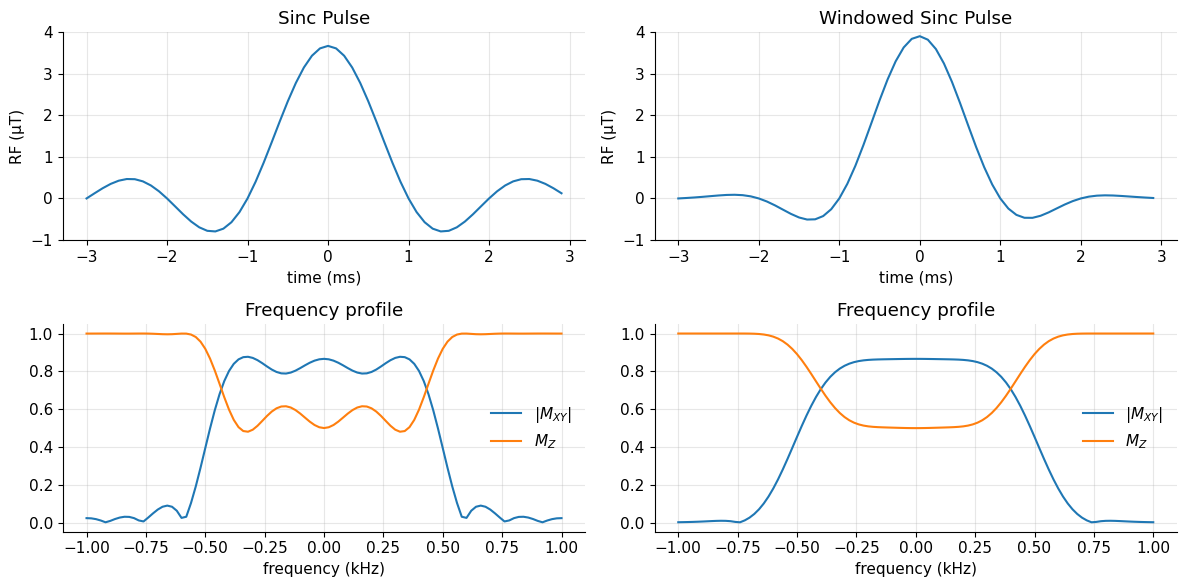

In [2]:
dt = 0.1e-3                    # 0.1 ms
flip = np.deg2rad(60.0)
tmax = 6e-3
N = int(round(tmax / dt))
t = (np.arange(N) - N // 2) * dt          # [s], centred
df = np.linspace(-1000, 1000, 101)         # [Hz]

fig, axs = plt.subplots(2, 2, figsize=(12, 6))
RF_sinc = scale_to_flip(np.sinc(t / 1e-3), flip, dt)
RF_win = scale_to_flip(np.hamming(N) * np.sinc(t / 1e-3), flip, dt)
for col, (RF, name) in enumerate([(RF_sinc, "Sinc Pulse"), (RF_win, "Windowed Sinc Pulse")]):
    mxy, mz, _ = bloch_profile(RF, dt, df)
    axs[0, col].plot(t * 1e3, RF * 1e6)
    axs[0, col].set(xlabel="time (ms)", ylabel="RF (µT)", ylim=(-1, 4), title=name)
    axs[1, col].plot(df / 1e3, mxy, label=r"$|M_{XY}|$"); axs[1, col].plot(df / 1e3, mz, label=r"$M_{Z}$")
    axs[1, col].set(title="Frequency profile", xlabel="frequency (kHz)"); axs[1, col].legend()
fig.tight_layout(); plt.show()

*Interpretation:* the abruptly truncated sinc (left) produces visible ripples inside and outside the passband; the Hamming-windowed sinc (right) has a flat passband and a clean stopband, with slightly less steep edges.

## Windowed-sinc design procedure

A practical recipe (used in many vendor sequences and in your own experiments):

1. **Specify** flip angle $\theta$, slice thickness $\Delta z$ (or spectral band $BW_{rf}$), and the available duration $T_{rf}$.
2. **Choose TBW** from the required sharpness: the transition width scales as $W\approx c/T_{rf}$ ($c$ ≈ 1–2 for windowed sinc, see below), so the edges are sharp *relative to the band* when $W\ll BW_{rf}$, i.e. $TBW=BW_{rf}T_{rf}\gg c$. Typical TBW: 2–4 for fast/low-SAR excitations, 6–12 for sharp slices or saturation bands.
3. **Build** $b_1(t)=A\,\mathrm{sinc}\!\big(TBW\,(t-T_{rf}/2)/T_{rf}\big)\,w(t)$ with a window $w$ (Hamming is the default).
4. **Scale** $A$ so that $\gamma\int b_1dt=\theta$, then check the peak $B_1$ and SAR ([E1](E1_RF_Pulses.ipynb)).
5. **Set the gradient** $G_{z,SS}=BW_{rf}/(\bar\gamma\Delta z)$ and the rewinder ([E2](E2_Slice_Selection.ipynb)).
6. **Verify** with a Bloch simulation – especially for θ ≳ 60°, where the Fourier design is no longer accurate.

In the small-tip regime the profile is the Fourier transform of $b_1$, so ripples and transition width can be read off the FT. The cell below measures them for several windows and durations.

In [3]:
def windowed_sinc(TBW, T_rf, n, theta, window="hamming"):
    """Windowed sinc with n samples over T_rf [s]; returns t (sample centres) [s], b1 [T], dt [s]."""
    dt = T_rf / n; t = (np.arange(n) + 0.5) * dt; x = (t - T_rf / 2) / T_rf
    w = {"none": np.ones(n), "hamming": 0.54 + 0.46 * np.cos(2 * np.pi * x),
         "hann": 0.5 + 0.5 * np.cos(2 * np.pi * x), "blackman": np.blackman(n)}[window]
    return t, scale_to_flip(np.sinc(TBW * x) * w, theta, dt).astype(complex), dt

def small_tip_profile(b1, t, dt, f):
    """|M_xy| predicted by the small-tip approximation (normalized to the centre)."""
    P = np.abs(np.exp(2j * np.pi * np.outer(f, t - t.mean())) @ b1)
    return P / P[np.argmin(np.abs(f))]

def ripple_metrics(f, P, BW):
    """Passband ripple (inner 60 % of band), stopband ripple (beyond 1.5x the half-width), transition width 90%->10%."""
    pas, stop, pos = np.abs(f) < 0.3 * BW, np.abs(f) > 0.75 * BW, f >= 0
    fp, Pp = f[pos], P[pos]; i90 = np.where(Pp >= 0.9)[0].max(); i10 = i90 + np.argmax(Pp[i90:] <= 0.1)
    return np.max(np.abs(P[pas] - 1)), P[stop].max(), fp[i10] - fp[i90]

f = np.linspace(-6000, 6000, 3001)
print(f"{'window':9s} {'T_rf':>6s} {'TBW':>4s} {'delta1':>8s} {'delta2':>8s} {'W [Hz]':>7s} {'W*T_rf':>7s} {'W/BW':>6s}")
for window in ["none", "hamming", "hann", "blackman"]:
    for T_rf, TBW in [(2e-3, 4), (4e-3, 8), (4e-3, 4)]:
        t_ws, b1_ws, dts = windowed_sinc(TBW, T_rf, 400, np.deg2rad(10), window)
        P = small_tip_profile(b1_ws, t_ws, dts, f)
        d1, d2, W = ripple_metrics(f, P, TBW / T_rf)
        print(f"{window:9s} {T_rf*1e3:5.0f}ms {TBW:4d} {d1:8.4f} {d2:8.4f} {W:7.0f} {W*T_rf:7.2f} {W*T_rf/TBW:6.2f}")

window      T_rf  TBW   delta1   delta2  W [Hz]  W*T_rf   W/BW
none          2ms    4   0.2434   0.0768     404    0.81   0.20
none          4ms    8   0.1087   0.0404     216    0.86   0.11


none          4ms    4   0.2434   0.0768     204    0.82   0.20
hamming       2ms    4   0.1326   0.0770     924    1.85   0.46
hamming       4ms    8   0.0047   0.0027     460    1.84   0.23


hamming       4ms    4   0.1301   0.0770     464    1.86   0.46
hann          2ms    4   0.1595   0.0889     996    1.99   0.50
hann          4ms    8   0.0050   0.0063     492    1.97   0.25


hann          4ms    4   0.1570   0.0889     500    2.00   0.50
blackman      2ms    4   0.1774   0.1435    1152    2.30   0.58
blackman      4ms    8   0.0372   0.0103     600    2.40   0.30


blackman      4ms    4   0.1749   0.1435     576    2.30   0.58


*Interpretation:*
* For each window the transition width times the duration, $W\cdot T_{rf}$, is (nearly) a constant: **only a longer pulse makes the edges steeper in Hz**. At fixed $T_{rf}$, a higher TBW gives a wider band with the same absolute edge width – so the edges become sharper *relative to the band* ($W/BW\propto1/TBW$).
* Windows trade ripple for transition width: no window → ~10–25 % ripple but the steepest edges; Hamming/Hann (TBW 8) → < 1 % ripple at about 2× the transition width; Blackman → wider transition still.

> **TODO (polish):** the ripple metric uses fixed band fractions (inner 60 %, beyond 1.5× half-width); for TBW 4 with a window the "passband ripple" column mostly measures the rounded top / transition, not true ripple. Replace by a proper band-edge-based definition.
* There is no free lunch: for a given duration, you choose a point on the ripple-vs-sharpness trade-off. The SLR algorithm with optimal filter design (least squares or Parks–McClellan "equiripple") gives the best possible trade-off for specified $\delta_1$, $\delta_2$.

## Time–bandwidth product and pulse selectivity

Arguably the most important RF pulse design parameter is the **time–bandwidth product**. As the name implies, this is the pulse duration (time) times the pulse bandwidth:

$$ TBW = T_{rf} \times BW_{rf} .$$

*In words:* a dimensionless number, fixed by the pulse *shape*; stretching the shape in time shrinks its bandwidth by the same factor.

where $T_{rf}$ [s] is the duration and $BW_{rf}$ [Hz] the bandwidth. A given RF pulse shape has an associated TBW, and the shape can be stretched or shrunk in time to modulate the resulting bandwidth.

The key feature of the TBW is that it controls the **pulse selectivity** – how sharp the pulse profile is, i.e. how quickly the profile goes from the desired flip angle to zero flip angle *relative to its bandwidth*. (Port of the original cell; 100 samples per pulse, 60°.)

TBW = 4, Trf = 4 ms: BW = 1000 Hz, peak B1 = 3.90 uT, energy = 0.012 uT^2 s
TBW = 4, Trf = 8 ms: BW = 500 Hz, peak B1 = 1.95 uT, energy = 0.006 uT^2 s
TBW = 8, Trf = 8 ms: BW = 1000 Hz, peak B1 = 3.92 uT, energy = 0.014 uT^2 s


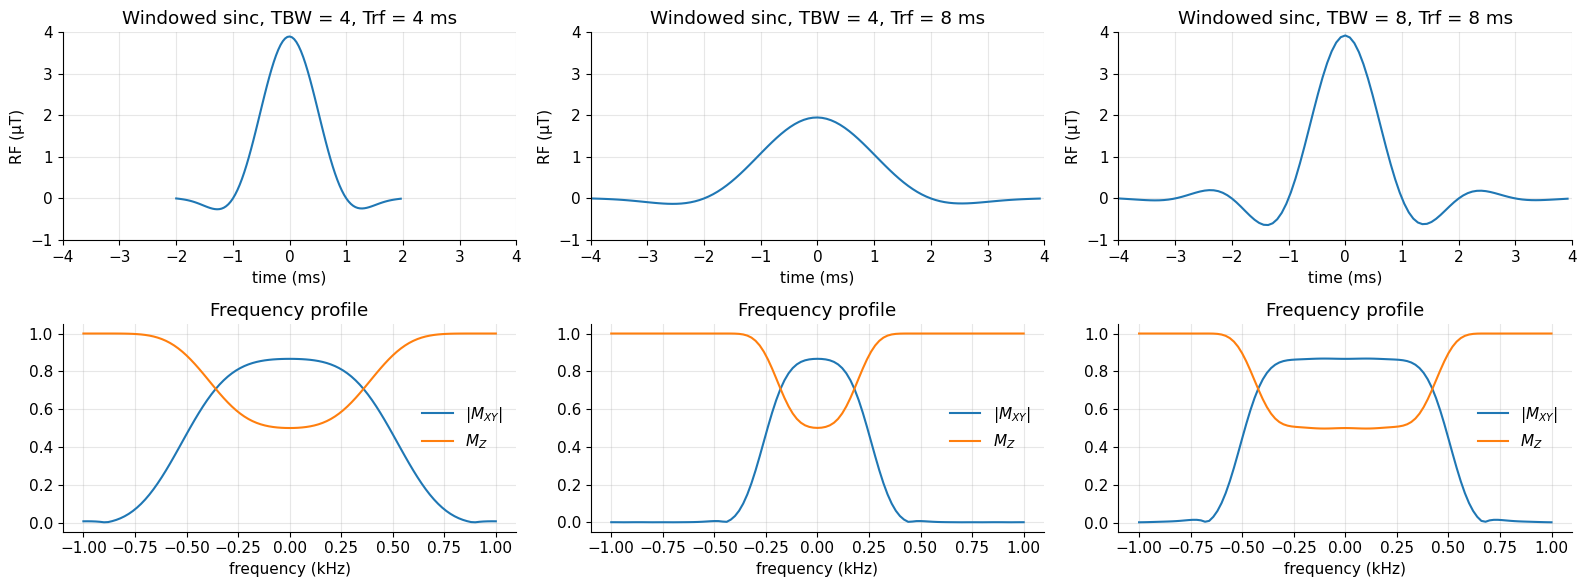

In [4]:
cases = [(4, 4e-3, "TBW = 4, Trf = 4 ms"), (4, 8e-3, "TBW = 4, Trf = 8 ms"), (8, 8e-3, "TBW = 8, Trf = 8 ms")]
Np = 100                      # samples per pulse
df = np.linspace(-1000, 1000, 101)
fig, axs = plt.subplots(2, 3, figsize=(16, 6))
for i, (TBW, Trf, title) in enumerate(cases):
    IN = np.arange(-Np / 2, Np / 2) / Np
    RF_shape = np.hamming(Np) * np.sinc(IN * TBW)        # windowed sinc
    t_pulse = IN * Trf
    dt_pulse = Trf / Np
    RF = scale_to_flip(RF_shape, flip, dt_pulse)
    mxy, mz, _ = bloch_profile(RF, dt_pulse, df)
    axs[0, i].plot(t_pulse * 1e3, RF * 1e6)
    axs[0, i].set(xlim=(-4, 4), ylim=(-1, 4), xlabel="time (ms)", ylabel="RF (µT)", title=f"Windowed sinc, {title}")
    axs[1, i].plot(df / 1e3, mxy, label=r"$|M_{XY}|$"); axs[1, i].plot(df / 1e3, mz, label=r"$M_{Z}$")
    axs[1, i].set(xlabel="frequency (kHz)", title="Frequency profile"); axs[1, i].legend()
    print(f"{title}: BW = {TBW/Trf:.0f} Hz, peak B1 = {np.abs(RF).max()*1e6:.2f} uT, "
          f"energy = {np.sum(RF**2)*dt_pulse*1e12:.3f} uT^2 s")
fig.tight_layout(); plt.show()

Notice that the higher-TBW pulse has a much sharper frequency profile for the same pulse duration, relative to its bandwidth (right vs. middle). But also: **higher peak power** – the printout shows ~2× the peak $B_1$ (→ 4× peak power) and ~2× the RF energy (SAR) of the TBW-4 pulse of the same duration. Halving the duration at fixed TBW (left vs. middle) doubles the bandwidth and doubles the peak $B_1$.

## High-flip-angle pulse design

For small flip angles, the frequency profile of an RF pulse is approximately given by the Fourier transform. However, non-linearities in the Bloch equation cause this approximation to break down for large flip angles, as shown below by the resulting "ripples" in the frequency profile when the flip angle of the windowed sinc is increased from 60° to 90°.

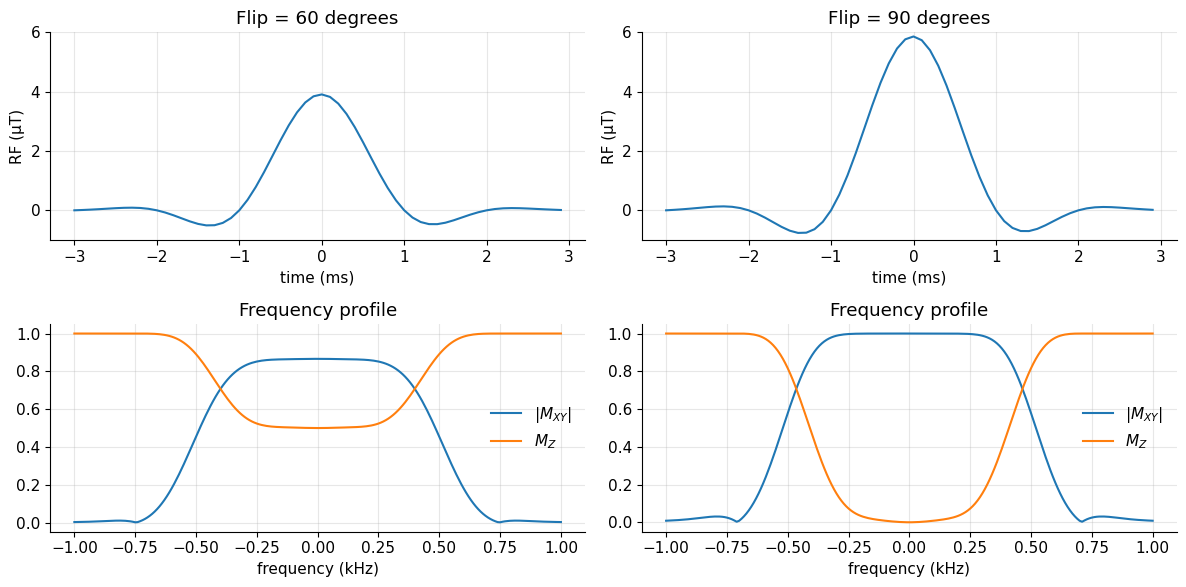

In [5]:
fig, axs = plt.subplots(2, 2, figsize=(12, 6))
RF_shape = np.hamming(N) * np.sinc(t / 1e-3)      # same 6 ms, TBW 6 windowed sinc as above
df = np.linspace(-1000, 1000, 201)
for col, flip_angle in enumerate([60, 90]):
    RF = scale_to_flip(RF_shape, np.deg2rad(flip_angle), dt)
    mxy, mz, _ = bloch_profile(RF, dt, df)
    axs[0, col].plot(t * 1e3, RF * 1e6)
    axs[0, col].set(xlabel="time (ms)", ylim=(-1, 6), ylabel="RF (µT)", title=f"Flip = {flip_angle} degrees")
    axs[1, col].plot(df / 1e3, mxy, label=r"$|M_{XY}|$"); axs[1, col].plot(df / 1e3, mz, label=r"$M_{Z}$")
    axs[1, col].set(xlabel="frequency (kHz)", title="Frequency profile"); axs[1, col].legend()
fig.tight_layout(); plt.show()

Note that with the Fourier-transform-based design, small ripples appear outside the desired slice at 90° (small bumps in $|M_{xy}|$ just outside the band edges), which were absent at 60°.

The solution is to use a more sophisticated pulse design that takes these non-linearities into account, such as the **Shinnar–Le Roux (SLR)** transform. The data folder contains two SLR pulses designed with John Pauly's `rf_tools` (`dzrf(59, 6, 'ex')` and `dzrf(59, 6, 'inv')`, a zero prepended): 60 samples, 0.1 ms apart (6 ms), TBW 6. Let's inspect them first.

In [6]:
ex_mat = loadmat("../data/RFpulse_excitation_tbw6_SLR.mat")
inv_mat = loadmat("../data/RFpulse_inversion_tbw6_SLR.mat")
print("keys:", [k for k in ex_mat if not k.startswith("__")], [k for k in inv_mat if not k.startswith("__")])
rf90_mT = ex_mat["rf_90_SLR"].ravel()          # complex, units: mT, one sample per 0.1 ms
rf180_mT = inv_mat["rf_inv_SLR"].ravel()
dt_slr = 0.1e-3
for name, rf in [("rf_90_SLR", rf90_mT), ("rf_inv_SLR", rf180_mT)]:
    b1 = rf * 1e-3                               # mT -> T
    print(f"{name}: {rf.size} samples, max |imag|/max|real| = {np.abs(rf.imag).max()/np.abs(rf.real).max():.1e}, "
          f"peak = {np.abs(b1).max()*1e6:.2f} uT, flip = gamma*sum(b1)*dt = {np.rad2deg(mt.GAMMA*np.sum(b1.real)*dt_slr):.1f} deg")

keys: ['rf_90_SLR'] ['rf_inv_SLR']
rf_90_SLR: 60 samples, max |imag|/max|real| = 2.7e-16, peak = 6.21 uT, flip = gamma*sum(b1)*dt = 90.0 deg
rf_inv_SLR: 60 samples, max |imag|/max|real| = 1.4e-12, peak = 23.25 uT, flip = gamma*sum(b1)*dt = 180.0 deg


*Interpretation:* the pulses are real-valued (the imaginary part is numerical noise), stored in **mT** for a 0.1 ms raster: with $\theta=\gamma\sum b_1\Delta t$ they give exactly 90° and 180°. The peak amplitudes, 6.2 µT and 23 µT, are realistic for a 6 ms pulse – the 180° pulse is near typical body-coil limits.

The 90° comparison (port of the original cell):

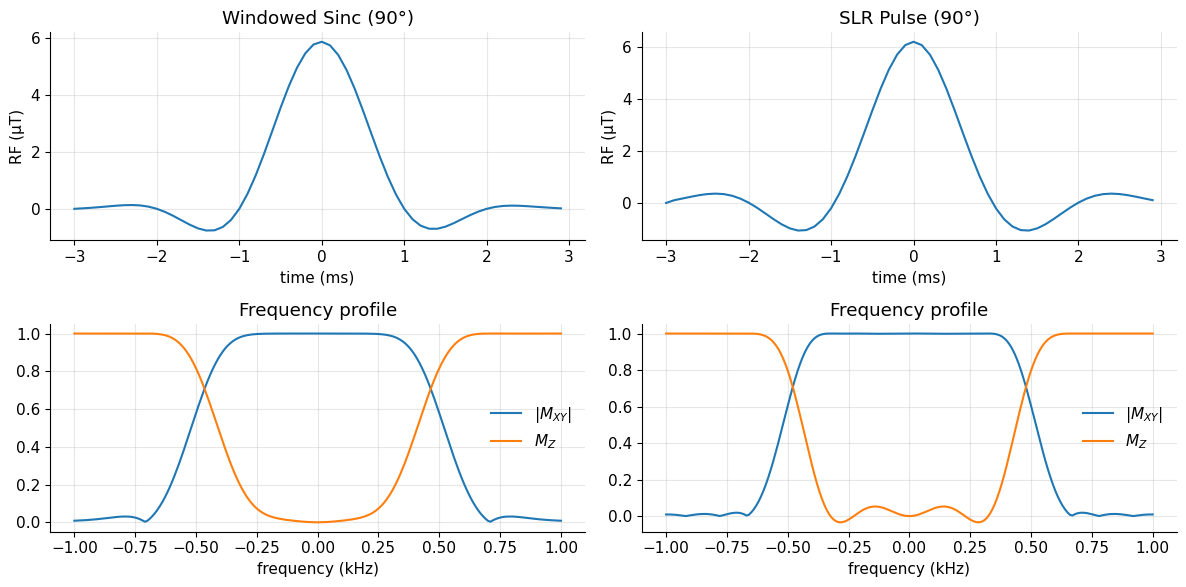

In [7]:
flip = np.deg2rad(90)
df = np.linspace(-1000, 1000, 201)
RF_win90 = scale_to_flip(np.hamming(N) * np.sinc(t / 1e-3), flip, dt)
RF_slr90 = scale_to_flip(rf90_mT.real, flip, dt_slr)      # rescale exactly to 90 degrees
t_slr = (np.arange(RF_slr90.size) - RF_slr90.size // 2) * dt_slr
fig, axs = plt.subplots(2, 2, figsize=(12, 6))
for col, (RF, tt, name) in enumerate([(RF_win90, t, "Windowed Sinc (90°)"), (RF_slr90, t_slr, "SLR Pulse (90°)")]):
    mxy, mz, _ = bloch_profile(RF, dt, df)
    axs[0, col].plot(tt * 1e3, RF * 1e6); axs[0, col].set(xlabel="time (ms)", ylabel="RF (µT)", title=name)
    axs[1, col].plot(df / 1e3, mxy, label=r"$|M_{XY}|$"); axs[1, col].plot(df / 1e3, mz, label=r"$M_{Z}$")
    axs[1, col].set(xlabel="frequency (kHz)", title="Frequency profile"); axs[1, col].legend()
fig.tight_layout(); plt.show()

Note that the ripples in the $M_{xy}$ profile are now removed! (There is some increased ripple in $M_z$, but this isn't an issue for excitation pulses.) The RF pulses themselves are only subtly different.

The degradation of the slice (frequency) profile of sinc pulses becomes substantial with a 180° inversion pulse:

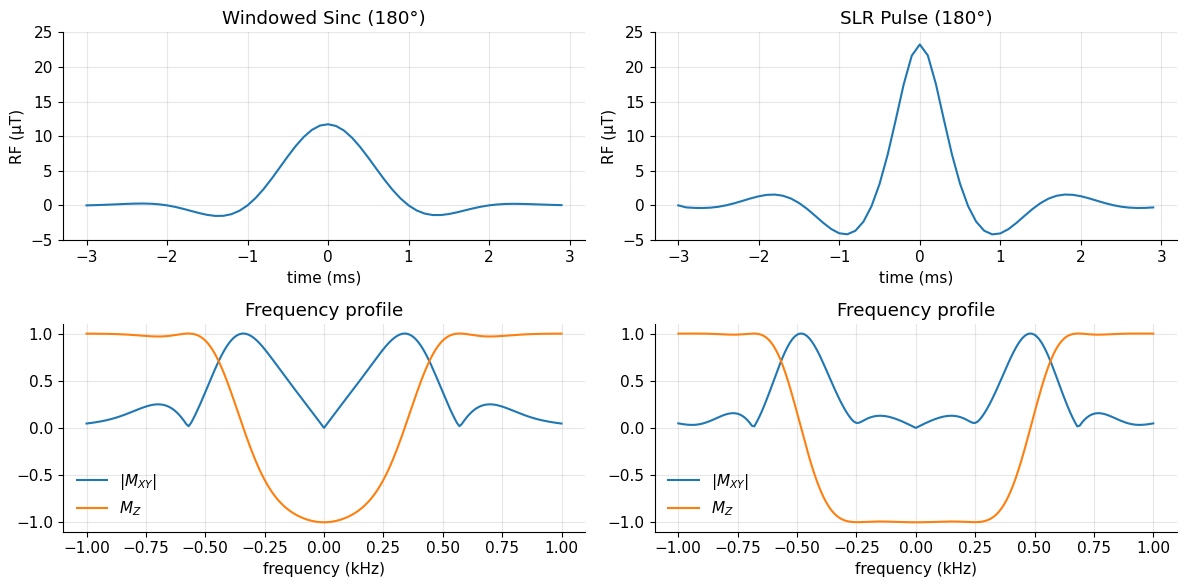

In [8]:
flip = np.deg2rad(180)
RF_win_inv = scale_to_flip(np.hamming(N) * np.sinc(t / 1e-3), flip, dt)
RF_slr_inv = scale_to_flip(rf180_mT.real, flip, dt_slr)
fig, axs = plt.subplots(2, 2, figsize=(12, 6))
for col, (RF, tt, name) in enumerate([(RF_win_inv, t, "Windowed Sinc (180°)"), (RF_slr_inv, t_slr, "SLR Pulse (180°)")]):
    mxy, mz, _ = bloch_profile(RF, dt, df)
    axs[0, col].plot(tt * 1e3, RF * 1e6); axs[0, col].set(xlabel="time (ms)", ylabel="RF (µT)", ylim=(-5, 25), title=name)
    axs[1, col].plot(df / 1e3, mxy, label=r"$|M_{XY}|$"); axs[1, col].plot(df / 1e3, mz, label=r"$M_{Z}$")
    axs[1, col].set(xlabel="frequency (kHz)", title="Frequency profile"); axs[1, col].legend()
fig.tight_layout(); plt.show()

Note that the inversion profile $M_z$ is much more selective – more like a rectangular function – with the SLR pulse design. The SLR RF pulse is now noticeably different from a windowed sinc (larger side lobes, which "pre-tilt" the magnetization so that the non-linear Bloch dynamics end up producing a sharp inversion).

## The Shinnar–Le Roux (SLR) algorithm

The SLR algorithm (Shinnar 1989; Le Roux 1988; Pauly, Le Roux, Nishimura & Macovski, *IEEE Trans. Med. Imaging* 1991) solves the large-flip-angle design problem **exactly** within a well-controlled approximation. The idea in four steps:

1. Describe each rotation by two complex numbers $(\alpha,\beta)$ instead of a 3×3 matrix.
2. Approximate the pulse as a sequence of short "hard" RF rotations separated by free precession (the **hard-pulse approximation**).
3. Then $\alpha$ and $\beta$ of the whole pulse are **polynomials** in $z=e^{-i2\pi\Delta f\Delta t_{rf}}$ – i.e. FIR filters with $N$ taps evaluated at frequency $\Delta f$.
4. Design $\beta$ with any digital-filter tool (windowed sinc, least squares, Parks–McClellan), compute a matching $\alpha$, and run the recursion backwards (**inverse SLR transform**) to obtain the RF samples.

### Step 1 – Cayley–Klein parameters (spinors)

Any rotation of $\vec M$ by an angle $\varphi$ about a unit axis $\hat n=[n_x,n_y,n_z]$ can be written as a 2×2 complex **unitary** matrix acting on "spinors" (this is how quantum mechanics describes spin-½ rotations, but here it is just a compact bookkeeping trick):

$$Q=\begin{bmatrix}\alpha&-\beta^*\\ \beta&\alpha^*\end{bmatrix},\qquad
\alpha=\cos\tfrac{\varphi}{2}+i\,n_z\sin\tfrac{\varphi}{2},\qquad
\beta=i\,(n_x+in_y)\sin\tfrac{\varphi}{2}.$$

*In words:* $\alpha$ encodes how much of the rotation is "about z" (precession) and $\beta$ how much is "about an axis in the x–y plane" (nutation, i.e. tipping); half-angles appear because spinors rotate "at half speed".

where $\varphi$ [rad] is the rotation angle, $\hat n$ the axis, $\alpha,\beta$ complex with $|\alpha|^2+|\beta|^2=1$. These formulas correspond to our **left-handed** rotation convention ($d\vec M/dt=\gamma\vec M\times\vec B$, precession $e^{-i\omega t}$, same as `mt.bloch_rotate`). Two consecutive rotations combine by matrix multiplication, $Q_{total}=Q_2Q_1$, i.e.

$$\alpha_{new}=a\,\alpha-b^*\beta,\qquad \beta_{new}=b\,\alpha+a^*\beta ,$$

*In words:* to add one more rotation $(a,b)$ after the rotation $(\alpha,\beta)$, multiply 2×2 matrices – only 2 complex numbers per step instead of 9 real ones.

where $(a,b)$ are the Cayley–Klein parameters of the new rotation.

**From $(\alpha,\beta)$ to magnetization** (derived by applying $Q$ to $\vec M$ written as the matrix $\begin{bmatrix}M_z&M_{xy}^*\\M_{xy}&-M_z\end{bmatrix}$ and computing $Q\,(\cdot)\,Q^\dagger$):

$$\text{excitation from } M_z=M_0:\quad M_{xy}^+=2\alpha^*\beta\,M_0,\qquad M_z^+=(|\alpha|^2-|\beta|^2)M_0=(1-2|\beta|^2)M_0 ,$$

$$\text{refocusing of existing } M_{xy}^-:\quad M_{xy}^+=(\alpha^*)^2M_{xy}^- - \beta^2\,(M_{xy}^-)^* .$$

*In words:* the **excitation** profile is $2\alpha^*\beta$; the **inversion** profile is $1-2|\beta|^2$; for a **spin echo** with crusher gradients around the refocusing pulse only the term with the mirrored phase $(M_{xy}^-)^*$ survives, so the refocusing efficiency is $|\beta|^2=\sin^2(\theta/2)$.

where $M_{xy}^\pm$ is the transverse magnetization just after/before the pulse and $|\beta|=\sin(\theta/2)$ for a rotation by $\theta$ about an axis in the x–y plane. So: **a 90° pulse needs $|\beta|=\sin45°=0.707$ in the passband; a 180° pulse needs $|\beta|=1$, and 0 in the stopband for all types.**

> **📐 Math note:** these relations correspond to John Pauly's `ab2ex` (2 conj(a)·b), `ab2inv` (1 − 2|b|²) and `ab2se` (i·b², with his sign convention for β). Our sign differs because we use the left-handed rotation convention of this course; all magnitudes are identical.

Below we implement the forward computation (the "abr" function of `rf_tools`) vectorized over many spins, and check it against `mt.bloch_simulate`.

In [9]:
def cayley_klein(rf, psi):
    """Forward SLR / 'abr': Cayley-Klein parameters of a pulse for many spins.
    rf  : (Nt,) complex RF rotation per sample [rad], i.e. gamma * b1 * dt (direction = phase)
    psi : (Nt, Ns) or (Ns,) precession angle per sample [rad] of each spin (2 pi df dt + gamma G.r dt)
    Each sample is an exact rotation about [Re rf, Im rf, psi] (left-handed), applied in time order.
    Returns alpha, beta of shape (Ns,)."""
    psi = np.atleast_2d(psi)
    a = np.ones(psi.shape[-1], complex); b = np.zeros(psi.shape[-1], complex)
    for n in range(len(rf)):
        bx, by = rf[n].real, rf[n].imag
        bz = psi[n] if psi.shape[0] > 1 else psi[0]
        phi = np.sqrt(bx**2 + by**2 + bz**2)                   # rotation angle of this step
        s = np.sin(phi / 2) / np.where(phi == 0, 1.0, phi)     # sin(phi/2) / phi  (axis normalization)
        ar = np.cos(phi / 2) + 1j * bz * s                     # alpha of this step
        br = 1j * (bx + 1j * by) * s                           # beta of this step
        a, b = ar * a - np.conj(br) * b, br * a + np.conj(ar) * b
    return a, b

# check against the Bloch simulator for the SLR 90 pulse and the windowed-sinc 180 pulse
df = np.linspace(-2000, 2000, 201)
for name, b1, dts in [("SLR 90", RF_slr90, dt_slr), ("sinc 180", RF_win_inv, dt)]:
    a, b = cayley_klein(mt.GAMMA * b1 * dts, 2 * np.pi * df * dts)
    _, Mz_b, Mxy_b = bloch_profile(b1, dts, df)
    print(f"{name}: max |2 a* b - Mxy(Bloch)| = {np.abs(2*np.conj(a)*b - Mxy_b).max():.1e}, "
          f"max |1-2|b|^2 - Mz(Bloch)| = {np.abs(1-2*np.abs(b)**2 - Mz_b).max():.1e}")
# refocusing relation, starting from Mxy = 1 (along x) and Mxy = i (along y)
a, b = cayley_klein(mt.GAMMA * RF_slr_inv * dt_slr, 2 * np.pi * df * dt_slr)
for m0 in [(1, 0, 0), (0, 1, 0)]:
    _, M = mt.bloch_simulate(B1=RF_slr_inv.astype(complex), dt=dt_slr, df=df, M_init=m0, return_all=False)
    m = m0[0] + 1j * m0[1]
    pred = np.conj(a)**2 * m - b**2 * np.conj(m)
    print(f"refocusing check, M_init={m0}: max error = {np.abs(pred - (M[:, 0] + 1j*M[:, 1])).max():.1e}")

SLR 90: max |2 a* b - Mxy(Bloch)| = 1.7e-15, max |1-2|b|^2 - Mz(Bloch)| = 3.8e-15
sinc 180: max |2 a* b - Mxy(Bloch)| = 1.3e-15, max |1-2|b|^2 - Mz(Bloch)| = 3.1e-15
refocusing check, M_init=(1, 0, 0): max error = 1.2e-14
refocusing check, M_init=(0, 1, 0): max error = 1.2e-14


*Interpretation:* the spinor computation agrees with the 3D Bloch rotation to machine precision ($10^{-15}$), and the refocusing formula is confirmed. The spinor form is also cheaper (2 complex numbers per spin and step), which matters for the 2D simulations in [J2](J2_Spectral-Spatial_RF_Pulses.ipynb).

### Step 2–3 – hard-pulse approximation and the SLR polynomials

Split the pulse into $N$ samples of length $\Delta t_{rf}$. Within sample $j$ assume the RF acts first as an instantaneous rotation by $\varphi_j=\gamma|b_{1,j}|\Delta t_{rf}$ about the axis $(\cos\vartheta_j,\sin\vartheta_j,0)$, followed by free precession by $\psi=2\pi\Delta f\,\Delta t_{rf}$ about z. For the RF part $C_j=\cos(\varphi_j/2)$, $S_j=ie^{i\vartheta_j}\sin(\varphi_j/2)$; free precession contributes the factor $z=e^{-i\psi}$. Dropping a common phase factor, the recursion is

$$A_j(z)=C_jA_{j-1}(z)-S_j^*B_{j-1}(z),\qquad B_j(z)=z\,\big[S_jA_{j-1}(z)+C_jB_{j-1}(z)\big],\qquad A_0=1,\ B_0=0 .$$

*In words:* each RF sample mixes the two polynomials (like one stage of a lattice filter), and each free-precession interval multiplies by $z$ – a one-sample delay in DSP language.

where $A_j$, $B_j$ are $\alpha$ and $\beta$ (up to a phase factor that cancels in all magnetization formulas) after $j$ samples, as functions of $z=e^{-i2\pi\Delta f\Delta t_{rf}}$. After $N$ samples, $A_N$ is a polynomial of degree $N-1$ in $z$ and $B_N/z$ also; on the unit circle

$$B_N\!\left(e^{-i2\pi\Delta f\Delta t_{rf}}\right)=\sum_{k=0}^{N-1}\beta_k\,e^{-i2\pi\Delta f\Delta t_{rf}(k+1)} ,$$

*In words:* the β-profile as a function of frequency is exactly the frequency response (DTFT) of an $N$-tap FIR filter with coefficients $\beta_k$.

where $\beta_k$ are the polynomial coefficients. That is the key insight: **designing an RF pulse = designing an FIR filter $B(z)$** with $|B|=\sin(\theta/2)$ in the passband and $|B|\approx0$ in the stopband. Everything you know about FIR design (window method, least squares, equiripple/Parks–McClellan, minimum-phase filters) carries over. The FIR frequency axis is periodic with period $1/\Delta t_{rf}$ – the profile **repeats** every $1/\Delta t_{rf}$ Hz (e.g. every 10 kHz for 0.1 ms sampling) – the excitation analogue of aliasing ([RM5](../refreshers/RM5_Fourier_Pairs_and_Sampling.ipynb)).

### Step 4 – the inverse SLR transform

Given $B_N$, we need $A_N$ with $|A_N|^2=1-|B_N|^2$ on the unit circle (energy conservation). The magnitude is fixed; the phase is free, and the usual choice is the **minimum-phase** $A_N$ (it gives the minimum-energy pulse); it is computed from $\log|A_N|$ with a Hilbert transform (the "cepstrum" trick). Then the recursion is run **backwards**: the lowest coefficients determine the last RF sample, $S_N/C_N=\beta_0/a_0$, which is undone, the polynomials shrink by one degree, and so on until all $N$ samples are known.

<details><summary><b>📐 Why the lowest coefficients give the last sample (optional)</b></summary>

Undoing the last RF sample: $\begin{bmatrix}A_{N-1}\\ zB_{N-1}\end{bmatrix}=\begin{bmatrix}C_N&S_N^*\\-S_N&C_N\end{bmatrix}\begin{bmatrix}A_N\\ B_N/z\end{bmatrix}$. Since $zB_{N-1}$ must have no constant term, $-S_Na_0+C_N\tilde\beta_0=0$ where $a_0$, $\tilde\beta_0$ are the constant coefficients of $A_N$ and $B_N/z$. Hence $S_N/C_N=\tilde\beta_0/a_0$, and with $C_N^2+|S_N|^2=1$ both are determined; $\varphi_N=2\arctan(|S_N|/C_N)$ and $e^{i\vartheta_N}=-iS_N/|S_N|$. (That the top coefficient of $A_{N-1}$ also vanishes is guaranteed by $|A|^2+|B|^2=1$.)

</details>

The pulse-type dependent targets and ripple conversions (from John Pauly's `dzrf`): an *excitation* pulse ($M_{xy}$ ripple $\delta_1$, $\delta_2$) needs $|B|=1/\sqrt2$ with $\beta$-ripples $\sqrt{\delta_1/2}$, $\delta_2/\sqrt2$; an *inversion* pulse ($M_z$ ripple) needs $|B|=1$ with $\delta_1/8$, $\sqrt{\delta_2/2}$; a *spin-echo* pulse needs $|B|=1$ with $\delta_1/4$, $\sqrt{\delta_2}$. (These follow from $M_{xy}=2\alpha^*\beta$, $M_z=1-2|\beta|^2$, $|\beta|^2$ by first-order error propagation.)

Here is a compact Python port of the relevant parts of `rf_tools` (`dzrf`, `dzls`, `dinf`, `b2a`, `cabc2rf`), written in our convention:

ex: flip = 91.3 deg, max imag = 1.8e-18
inv: flip = 173.7 deg, max imag = 8.0e-17


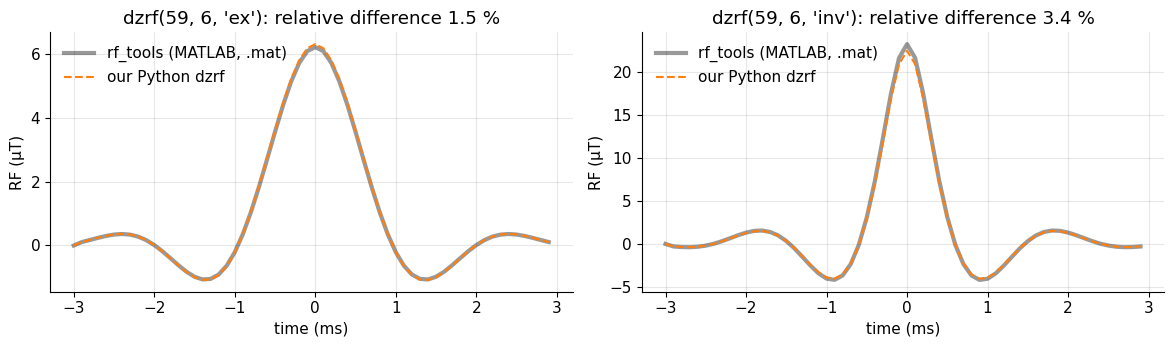

In [10]:
from scipy.signal import remez

def dinf(d1, d2):
    """Empirical transition-width factor D_inf(d1, d2) of an optimal linear-phase FIR (Herrmann et al.)."""
    a1, a2, a3, a4, a5, a6 = 5.309e-3, 7.114e-2, -4.761e-1, -2.66e-3, -5.941e-1, -4.278e-1
    l1, l2 = np.log10(d1), np.log10(d2)
    return (a1 * l1**2 + a2 * l1 + a3) * l2 + (a4 * l1**2 + a5 * l1 + a6)

def fir_lowpass(n, tbw, d1=0.01, d2=0.01, ftype="ls", n_grid=4096):
    """Linear-phase low-pass FIR with n taps and time-bandwidth tbw (band edges in cycles/sample).
    ftype 'ls': weighted least squares (like MATLAB firls), 'pm': Parks-McClellan equiripple (remez),
    'ms': Hamming-windowed sinc."""
    w = dinf(d1, d2) / tbw
    fp, fs = (1 - w) * tbw / (2 * n), (1 + w) * tbw / (2 * n)     # passband / stopband edge
    if ftype == "pm":
        return remez(n, [0, fp, fs, 0.5], [1, 0], weight=[1, d1 / d2], fs=1)
    if ftype == "ms":
        x = (np.arange(n) - (n - 1) / 2) / n
        h = np.sinc(tbw * x) * (0.54 + 0.46 * np.cos(2 * np.pi * x)); return h / h.sum()
    f = np.linspace(0, 0.5, n_grid); keep = (f <= fp) | (f >= fs)
    f, d = f[keep], (f[keep] <= fp).astype(float)
    wt = np.where(f <= fp, 1.0, d1 / d2)
    A = np.cos(2 * np.pi * np.outer(f, np.arange(n) - (n - 1) / 2))
    return np.linalg.lstsq(A * np.sqrt(wt)[:, None], d * np.sqrt(wt), rcond=None)[0]

def b2a(b):
    """Minimum-phase alpha polynomial with |A|^2 = 1 - |B|^2 on the unit circle (cepstrum / Hilbert method)."""
    n = len(b); M = 16 * 2 ** int(np.ceil(np.log2(n)) + 1)
    B = np.fft.fft(b, M)
    if np.abs(B).max() >= 1:
        B = B / (np.abs(B).max() + 1e-7)
    c = np.fft.ifft(np.log(np.sqrt(1 - np.abs(B)**2)))     # real cepstrum of |A|
    fold = np.zeros(M); fold[0] = fold[M // 2] = 1; fold[1:M // 2] = 2
    return np.fft.ifft(np.exp(np.fft.fft(c * fold)))[:n]     # minimum-phase sequence

def ab2rf(a, b):
    """Inverse SLR transform: polynomials a, b (constant coefficient first) -> RF rotations [rad] per sample."""
    a, b = np.array(a, complex), np.array(b, complex)
    rf = np.zeros(len(a), complex)
    for j in range(len(a) - 1, -1, -1):
        r = b[0] / a[0]
        C = 1 / np.sqrt(1 + abs(r)**2); S = C * r
        rf[j] = 2 * np.arctan2(abs(S), C) * (-1j * S / abs(S)) if abs(S) > 0 else 0.0
        a, b = (C * a + np.conj(S) * b)[:-1], (-S * a + C * b)[1:]
    return rf

def dzrf(n, tbw, ptype="st", ftype="ls", d1=0.01, d2=0.01):
    """SLR pulse design (port of rf_tools dzrf). ptype: 'st' small tip, 'ex' 90 excitation, 'inv' inversion,
    'se' spin-echo refocusing, 'sat' 90 saturation. Returns RF rotation per sample [rad] (real -> along +x)."""
    bsf, d1, d2 = {"st": (1, d1, d2), "ex": (np.sqrt(0.5), np.sqrt(d1 / 2), d2 / np.sqrt(2)),
                   "se": (1, d1 / 4, np.sqrt(d2)), "inv": (1, d1 / 8, np.sqrt(d2 / 2)),
                   "sat": (np.sqrt(0.5), d1 / 2, np.sqrt(d2))}[ptype]
    b = fir_lowpass(n, tbw, d1, d2, ftype)
    if ptype == "st":
        return b.astype(complex)
    b = 1j * bsf * b          # factor i: puts the RF axis along +x in our convention
    return ab2rf(b2a(b), b)

# Re-design the two pulses stored in ../data and compare
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for i, (ptype, ref) in enumerate([("ex", rf90_mT), ("inv", rf180_mT)]):
    rf = np.concatenate([[0], dzrf(59, 6, ptype)])            # same recipe as the .mat files
    b1 = rf / (mt.GAMMA * dt_slr)                              # rad per sample -> T
    ref_T = ref * 1e-3
    err = np.linalg.norm(b1 - ref_T) / np.linalg.norm(ref_T)
    ax[i].plot(t_slr * 1e3, ref_T.real * 1e6, "k", lw=3, alpha=0.4, label="rf_tools (MATLAB, .mat)")
    ax[i].plot(t_slr * 1e3, b1.real * 1e6, "C1--", label="our Python dzrf")
    ax[i].set(title=f"dzrf(59, 6, '{ptype}'): relative difference {err*100:.1f} %", xlabel="time (ms)", ylabel="RF (µT)")
    ax[i].legend(); print(f"{ptype}: flip = {np.rad2deg(np.sum(rf.real)):.1f} deg, max imag = {np.abs(rf.imag).max():.1e}")
plt.tight_layout(); plt.show()

*Interpretation:* our Python SLR reproduces the reference pulses to within a few % (the small difference comes from the least-squares filter routine, MATLAB `firls` vs our discretized version). The signed areas come out at ≈ 91° and ≈ 174° automatically – nobody told the algorithm to scale the area; the pulse follows from $|B|=\sin(\theta/2)$. (For large-angle SLR pulses the area is only approximately the flip angle: the *profile* is what is designed exactly, and the on-resonance rotation is indeed 90°/180°.)

### SLR profiles: excitation, inversion, refocusing

The next figure ports Larson's `RF_examples.m`: a TBW-10, 200-sample inversion pulse (6 ms) designed with SLR, its profiles when used for excitation ($|M_{xy}|$ from $M_z$), spin-echo refocusing ($|\beta|^2$) and inversion ($M_z$), and the underlying polynomials. Note that one pulse has *three different* profiles depending on what it is used for.

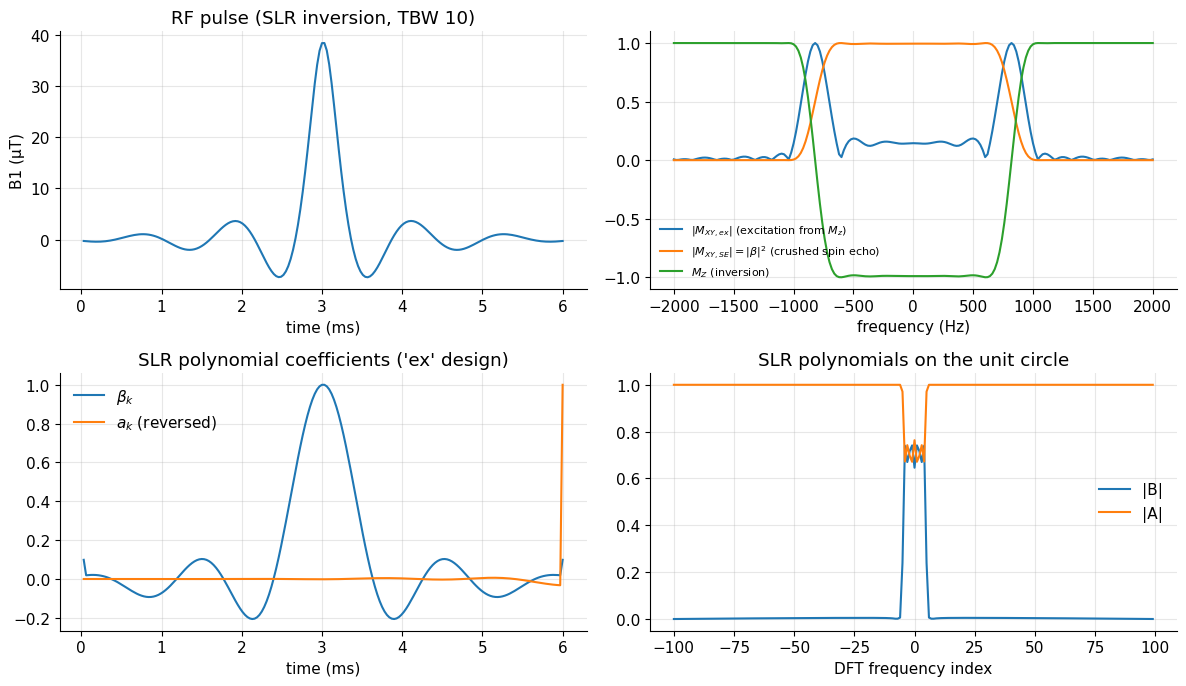

In [11]:
N_ex, tbw, T = 200, 10, 6e-3
dts = T / N_ex
rf = dzrf(N_ex, tbw, "inv", "ls")
df = np.linspace(-2000, 2000, 201)
a, b = cayley_klein(rf, 2 * np.pi * df * dts)
mxy_ex, mxy_se, mz = 2 * np.conj(a) * b, -b**2, 1 - 2 * np.abs(b)**2

# SLR polynomials of the 'ex' design (as in the original): beta from a Parks-McClellan filter, alpha min-phase
bpoly = np.sqrt(0.5) * fir_lowpass(N_ex, tbw, np.sqrt(0.01 / 2), 0.01 / np.sqrt(2), "pm")
apoly = b2a(bpoly)
Bf, Af = np.fft.fftshift(np.fft.fft(bpoly)), np.fft.fftshift(np.fft.fft(apoly))
tt = np.arange(1, N_ex + 1) * dts * 1e3
fig, axs = plt.subplots(2, 2, figsize=(12, 7))
axs[0, 0].plot(tt, (rf / (mt.GAMMA * dts)).real * 1e6); axs[0, 0].set(xlabel="time (ms)", ylabel="B1 (µT)", title="RF pulse (SLR inversion, TBW 10)")
axs[0, 1].plot(df, np.abs(mxy_ex), label=r"$|M_{XY,ex}|$ (excitation from $M_z$)")
axs[0, 1].plot(df, np.abs(mxy_se), label=r"$|M_{XY,SE}|=|\beta|^2$ (crushed spin echo)")
axs[0, 1].plot(df, mz, label=r"$M_Z$ (inversion)"); axs[0, 1].set(xlabel="frequency (Hz)"); axs[0, 1].legend(fontsize=8)
axs[1, 0].plot(tt, bpoly / bpoly.max(), label=r"$\beta_k$"); axs[1, 0].plot(tt, apoly.real[::-1] / apoly.real.max(), label=r"$a_k$ (reversed)")
axs[1, 0].set(xlabel="time (ms)", title="SLR polynomial coefficients ('ex' design)"); axs[1, 0].legend()
axs[1, 1].plot(np.arange(N_ex) - N_ex // 2, np.abs(Bf), label="|B|"); axs[1, 1].plot(np.arange(N_ex) - N_ex // 2, np.abs(Af), label="|A|")
axs[1, 1].set(xlabel="DFT frequency index", title="SLR polynomials on the unit circle"); axs[1, 1].legend()
plt.tight_layout(); plt.show()

*Interpretation:* top right – the same inversion pulse gives a sharp inversion band ($M_z=-1$), a sharp crushed-spin-echo band ($|\beta|^2=1$), but a *strange* excitation profile: $|M_{xy}|$ is zero in the centre (180° there) and maximal at the band edges, where the flip angle passes through 90°. Bottom – $\beta$ is a symmetric (linear-phase) FIR filter that looks like a windowed sinc; $\alpha$ is minimum phase (energy concentrated at one end); on the unit circle $|A|^2+|B|^2=1$: where $|B|=0.707$ (90° passband), $|A|=0.707$ too.

The time–bandwidth illustration of `RF_examples.m`: doubling TBW at the same duration sharpens the profile and widens the band; doubling the duration at the same TBW halves the band; peak $B_1$ follows.

TBW 10, 6 ms: BW = 1667 Hz, peak B1 = 10.5 uT
TBW 20, 12 ms: BW = 1667 Hz, peak B1 = 10.7 uT
TBW 20, 6 ms: BW = 3333 Hz, peak B1 = 21.5 uT


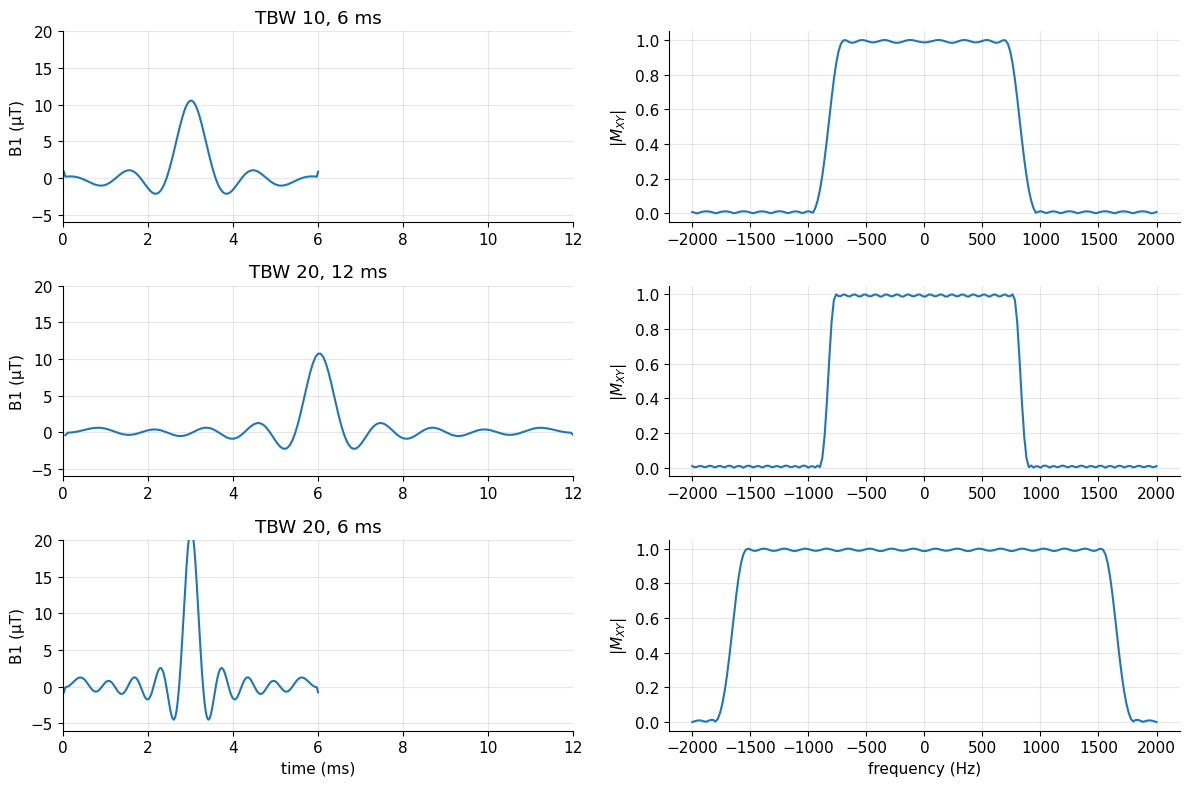

In [12]:
rf10 = dzrf(N_ex, tbw, "ex", "pm")
rf20 = dzrf(N_ex, 2 * tbw, "ex", "pm")
fig, axs = plt.subplots(3, 2, figsize=(12, 8))
for row, (rf_i, Ti, lab) in enumerate([(rf10, T, "TBW 10, 6 ms"), (rf20, 2 * T, "TBW 20, 12 ms"), (rf20, T, "TBW 20, 6 ms")]):
    dti = Ti / N_ex
    a, b = cayley_klein(rf_i, 2 * np.pi * df * dti)
    axs[row, 0].plot(np.arange(1, N_ex + 1) * dti * 1e3, (rf_i / (mt.GAMMA * dti)).real * 1e6)
    axs[row, 0].set(xlim=(0, 12), ylim=(-6, 20), ylabel="B1 (µT)", title=lab)
    axs[row, 1].plot(df, np.abs(2 * np.conj(a) * b)); axs[row, 1].set(ylabel=r"$|M_{XY}|$")
    print(f"{lab}: BW = {(tbw if row == 0 else 2*tbw)/Ti:.0f} Hz, peak B1 = {np.abs(rf_i).max()/(mt.GAMMA*dti)*1e6:.1f} uT")
axs[2, 0].set_xlabel("time (ms)"); axs[2, 1].set_xlabel("frequency (Hz)")
plt.tight_layout(); plt.show()

*Interpretation:* TBW 20 over 12 ms gives the same bandwidth as TBW 10 over 6 ms but with twice as steep edges, at the same peak $B_1$ (≈ 10.5 µT) and twice the duration; squeezing TBW 20 into 6 ms doubles the bandwidth and needs twice the peak $B_1$ (≈ 21.5 µT). These are the same rules as for windowed sinc – SLR only makes the profile *as good as possible* for a given TBW and ripple.

### Excitation vs inversion vs refocusing designs

`dzrf` produces different pulses for the different purposes, because the profile that matters is different ($2\alpha^*\beta$, $1-2|\beta|^2$ or $|\beta|^2$) and so are the ripple requirements. A common mistake is to "make a 180° pulse" by doubling the amplitude of a 90° pulse. Let's compare (128 samples, 4 ms, TBW 6), each pulse evaluated with the profile relevant for its purpose.

ex (90°)            : peak B1 =   9.3 uT, energy =  0.050 uT^2 s
inv (180°)          : peak B1 =  33.4 uT, energy =  0.373 uT^2 s
se (180°)           : peak B1 =  32.0 uT, energy =  0.353 uT^2 s
2 × ex (naive 180°) : peak B1 =  18.5 uT, energy =  0.200 uT^2 s


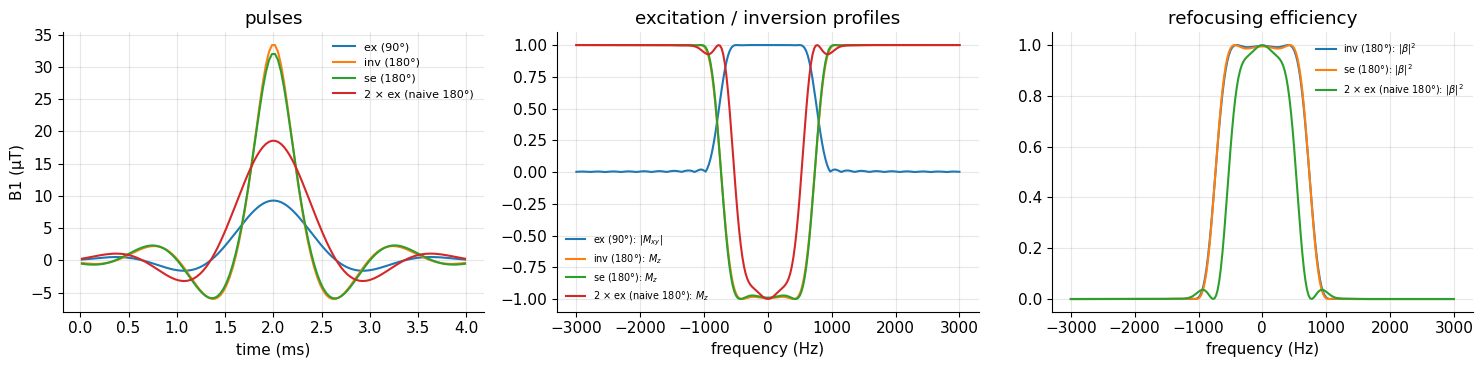

In [13]:
N2, T2, tbw2 = 128, 4e-3, 6
dt2 = T2 / N2
df = np.linspace(-3000, 3000, 241)
designs = {"ex (90°)": dzrf(N2, tbw2, "ex"), "inv (180°)": dzrf(N2, tbw2, "inv"), "se (180°)": dzrf(N2, tbw2, "se"),
           "2 × ex (naive 180°)": 2 * dzrf(N2, tbw2, "ex")}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for name, rf_i in designs.items():
    a, b = cayley_klein(rf_i, 2 * np.pi * df * dt2)
    tt = (np.arange(N2) + 0.5) * dt2 * 1e3
    axs[0].plot(tt, (rf_i / (mt.GAMMA * dt2)).real * 1e6, label=name)
    if name.startswith("ex"):
        axs[1].plot(df, np.abs(2 * np.conj(a) * b), label=name + r": $|M_{xy}|$")
    else:
        axs[1].plot(df, 1 - 2 * np.abs(b)**2, label=name + r": $M_z$")
        axs[2].plot(df, np.abs(b)**2, label=name + r": $|\beta|^2$")
    print(f"{name:20s}: peak B1 = {np.abs(rf_i).max()/(mt.GAMMA*dt2)*1e6:5.1f} uT, "
          f"energy = {np.sum(np.abs(rf_i/(mt.GAMMA*dt2))**2)*dt2*1e12:6.3f} uT^2 s")
axs[0].set(xlabel="time (ms)", ylabel="B1 (µT)", title="pulses"); axs[0].legend(fontsize=8)
axs[1].set(xlabel="frequency (Hz)", title="excitation / inversion profiles"); axs[1].legend(fontsize=7)
axs[2].set(xlabel="frequency (Hz)", title="refocusing efficiency"); axs[2].legend(fontsize=7)
plt.tight_layout(); plt.show()

*Interpretation:* the dedicated inversion and spin-echo designs give flat, sharp $M_z$ and $|\beta|^2$ profiles; the "doubled 90°" has a rounded, narrower effective band and ripples – it was optimized for a different non-linear target. The dedicated 180° SLR designs need ≈ 3.5× the peak $B_1$ and ≈ 7× the energy of the 90° design (more than the $\theta^2$ = 4× rule, because they have bigger side lobes), so in fast spin-echo trains the 180° pulses dominate SAR ([E1](E1_RF_Pulses.ipynb)).

> **🔧 Engineering reality:** Vendors use SLR (or closely related optimal-control) pulses for almost all slice-selective excitations, refocusing and inversion. Variants trade properties: **minimum-phase** SLR pulses (designed with a minimum-phase β) concentrate the energy at the end of the pulse, giving a shorter effective echo time; **VERSE** reshapes the pulse to the gradient waveform to reduce peak $B_1$ and SAR or to play the pulse on gradient ramps ([J2](J2_Spectral-Spatial_RF_Pulses.ipynb)); 2D/3D pulses use excitation k-space ([J1](J1_Excitation_K-space.ipynb)); parallel-transmit pulses compensate $B_1^+$ inhomogeneity at 3 T and 7 T ([B5](B5_RF_System_and_Receive_Chain.ipynb)).

## Adiabatic pulses (briefly)

All pulses so far rotate $\vec M$ by an angle proportional to the $B_1$ amplitude. If the transmit field is 20 % too weak (common at 3 T in the body, see [B5](B5_RF_System_and_Receive_Chain.ipynb)), a 180° pulse becomes a 144° pulse. **Adiabatic pulses** are a class of pulses that are basically insensitive to $B_1^+$ inhomogeneity, as long as $B_1$ exceeds a threshold.

**How they work.** Instead of a fixed frequency, the RF frequency is **swept** through resonance. In the rotating frame (at the carrier) the effective field is $\vec B_{eff}(t)=[\,|b_1(t)|,\ 0,\ -\Delta\omega_{rf}(t)/\gamma\,]$ (in a frame that follows the RF phase). At the start the RF is far off resonance, so $\vec B_{eff}$ points almost along $+z$ – parallel to $\vec M$. The sweep slowly turns $\vec B_{eff}$ through the x–y plane down to $-z$. If the turning is slow compared with the precession of $\vec M$ about $\vec B_{eff}$, $\vec M$ simply **follows** $\vec B_{eff}$ (it precesses in a tight cone around it) and ends up inverted – independent of the exact amplitude. The **adiabatic condition** is

$$\left|\frac{d\xi}{dt}\right|\ \ll\ \gamma\,|\vec B_{eff}(t)| ,$$

*In words:* the direction of the effective field must change much more slowly than the magnetization precesses around it.

where $\xi(t)$ [rad] is the angle of $\vec B_{eff}$ relative to the z-axis, and $\gamma|\vec B_{eff}|$ [rad/s] the precession rate about it.

The classic example is the **hyperbolic-secant (HS) pulse** (Silver, Joseph & Hoult 1984):

$$b_1(t)=A_0\,\mathrm{sech}(\kappa\tau),\qquad \Delta\omega_{rf}(t)=-\mu\kappa\tanh(\kappa\tau),\qquad \tau=t-T_{rf}/2 ,$$

*In words:* a bell-shaped amplitude, with a frequency that sweeps smoothly from $+\mu\kappa$ to $-\mu\kappa$ (rad/s) while the amplitude is high.

where $A_0$ [T] is the peak amplitude, $\kappa$ [s⁻¹] sets the sweep speed (books call it β), $\mu$ (dimensionless) the sweep width; it inverts a band of width $\approx\mu\kappa/\pi$ [Hz], and it is adiabatic if $A_0\gtrsim\sqrt\mu\,\kappa/\gamma$. The RF envelope is $b_1(t)e^{-i\int_0^t\Delta\omega_{rf}d\tau}$ (frequency shift as in [E1](E1_RF_Pulses.ipynb)).

HS pulse: inverted band ~ 1273 Hz, threshold A0 ~ 6.7 uT


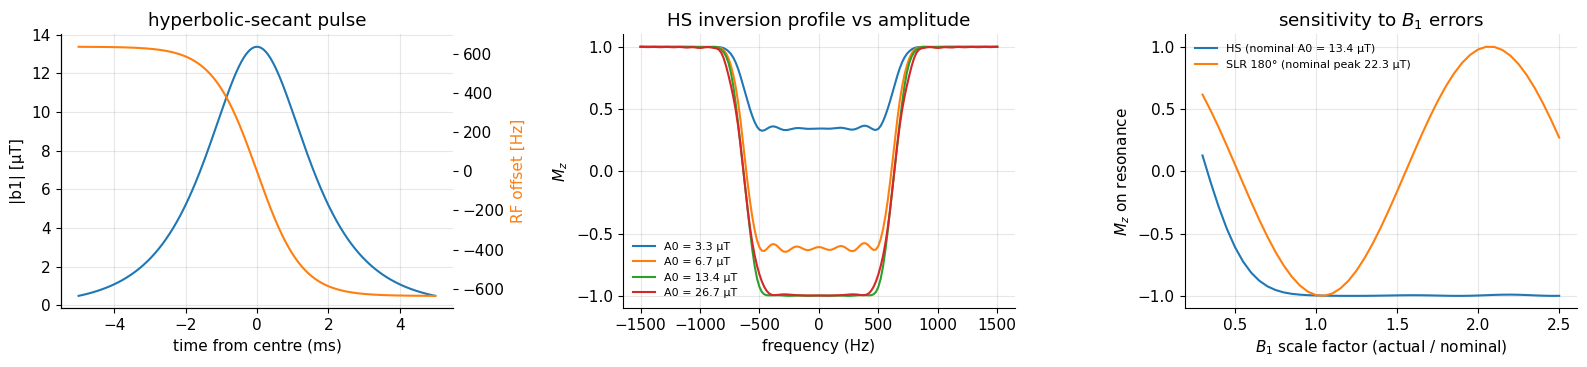

In [14]:
T_hs, dt_hs = 10e-3, 10e-6
n = int(round(T_hs / dt_hs)); tau = (np.arange(n) + 0.5) * dt_hs - T_hs / 2
kappa, mu = 800.0, 5.0
dw = -mu * kappa * np.tanh(kappa * tau)                       # RF frequency sweep [rad/s]
phase = np.cumsum(dw) * dt_hs                                 # integral of the sweep [rad]
A_thr = np.sqrt(mu) * kappa / mt.GAMMA                         # adiabatic threshold [T]
hs = lambda A0: A0 / np.cosh(kappa * tau) * np.exp(-1j * phase)
print(f"HS pulse: inverted band ~ {mu*kappa/np.pi:.0f} Hz, threshold A0 ~ {A_thr*1e6:.1f} uT")

df = np.linspace(-1500, 1500, 151)
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8))
axs[0].plot(tau * 1e3, np.abs(hs(2 * A_thr)) * 1e6, label="|b1| [µT]")
ax2 = axs[0].twinx(); ax2.plot(tau * 1e3, dw / (2 * np.pi), "C1", label="frequency sweep [Hz]"); ax2.grid(False)
axs[0].set(xlabel="time from centre (ms)", ylabel="|b1| [µT]", title="hyperbolic-secant pulse"); ax2.set_ylabel("RF offset [Hz]", color="C1")
for A0 in [0.5 * A_thr, 1 * A_thr, 2 * A_thr, 4 * A_thr]:
    _, mz, _ = bloch_profile(hs(A0), dt_hs, df)
    axs[1].plot(df, mz, label=f"A0 = {A0*1e6:.1f} µT")
axs[1].set(xlabel="frequency (Hz)", ylabel=r"$M_z$", title="HS inversion profile vs amplitude"); axs[1].legend(fontsize=8)

# B1 robustness: on-resonance Mz vs B1 scale, HS (nominal 2x threshold) vs SLR inversion pulse (nominal 180)
scales = np.linspace(0.3, 2.5, 45)
rf_inv = dzrf(128, 6, "inv"); dt_inv = 6e-3 / 128
mz_hs = [bloch_profile(hs(s * 2 * A_thr), dt_hs, [0.0])[1][0] for s in scales]
mz_slr = [bloch_profile(s * rf_inv / (mt.GAMMA * dt_inv), dt_inv, [0.0])[1][0] for s in scales]
axs[2].plot(scales, mz_hs, label=f"HS (nominal A0 = {2*A_thr*1e6:.1f} µT)")
axs[2].plot(scales, mz_slr, label=f"SLR 180° (nominal peak {np.abs(rf_inv).max()/(mt.GAMMA*dt_inv)*1e6:.1f} µT)")
axs[2].set(xlabel=r"$B_1$ scale factor (actual / nominal)", ylabel=r"$M_z$ on resonance", title="sensitivity to $B_1$ errors"); axs[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

*Interpretation:* above the threshold (≈ 6.7 µT here) the HS pulse inverts a broad band no matter how much stronger $B_1$ is; below it, inversion fails. The SLR 180° pulse inverts perfectly only at the nominal $B_1$ ($M_z=\cos(\text{scale}\cdot180°)$ on resonance), while the HS pulse gives $M_z\approx-1$ for any scale ≳ 0.6. The price: higher energy (SAR), long durations (~10 ms), and – used alone – a non-linear phase across the band, which is why adiabatic refocusing uses *pairs* of pulses. (At high $B_1$ the band edges get slightly worse here, because the truncated sweep of ±637 Hz no longer covers them adiabatically.)

The example below (SpinBench simulation from the original book) shows two 180° adiabatic inversion pulses. They "sweep" the magnetization from +z to −z, and then back again with the second pulse.

![Two adiabatic inversion pulses sweeping M from +z to -z and back](../images/adiabatic_gif.gif)

*Yellow – $B_1$ (RF) vector; white – net magnetizations for a range of frequencies around the Larmor frequency; bottom left – amplitude of the adiabatic pulses.* More adiabatic fun (pulse pairs, trajectories) in [J3 Fun with RF Pulses](J3_Fun_with_RF_Pulses.ipynb).

## Multi-band pulses (shift theorem)

**Simultaneous multi-slice** (SMS) imaging excites several slices at once and separates them with coil sensitivities ([H3 Accelerated Imaging](H3_Accelerated_Imaging_Methods.ipynb)). The excitation pulse is a **sum of frequency-shifted copies** of a single-band pulse. By the shift theorem, multiplying by $e^{-i2\pi f_bt}$ shifts the profile to $\Delta f=f_b$, i.e. to position $z_b=f_b/(\bar\gamma G_{z,SS})$:

$$b_1^{MB}(t)=b_1(t)\sum_{b=1}^{N_b}e^{-i2\pi f_b(t-T_{rf}/2)+i\phi_b},\qquad f_b=\bar\gamma\,G_{z,SS}\,z_b .$$

*In words:* add $N_b$ copies of the pulse, each tuned to a different slice position (and optionally given its own phase $\phi_b$).

where $b_1(t)$ [T] is the single-band pulse, $N_b$ the number of bands, $z_b$ [m] the slice positions, $G_{z,SS}$ [T/m] the slice-select gradient and $\phi_b$ [rad] optional band phases. Because the Bloch equation is non-linear, the sum works perfectly only in the small-tip regime, but in practice it is also used for 90° (and with care 180°) pulses as long as the bands are well separated.

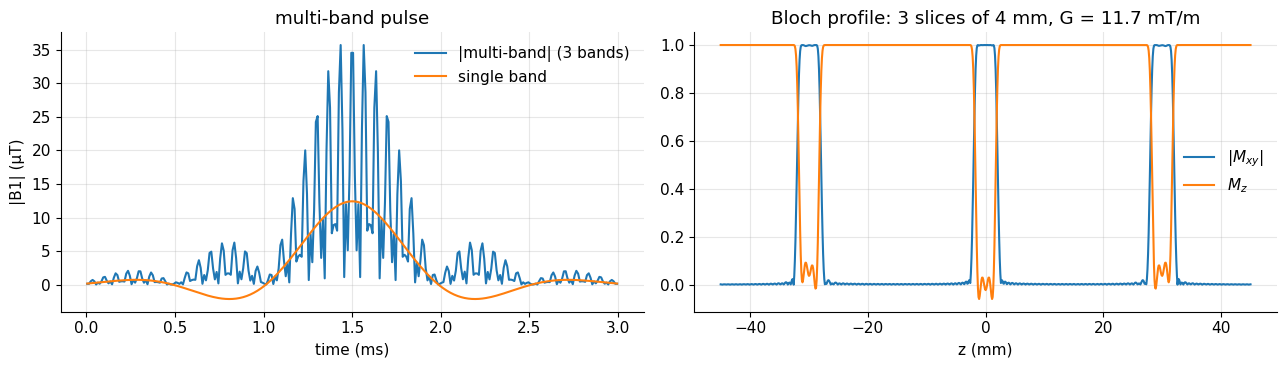

peak B1: single 12.4 uT, multi-band 35.7 uT (x2.9);  energy x3.00


In [15]:
dt_mb, T_mb, tbw_mb, dz_mb = 10e-6, 3e-3, 6, 4e-3
n = int(round(T_mb / dt_mb)); t_mb = (np.arange(n) + 0.5) * dt_mb
rf_sb = dzrf(n, tbw_mb, "ex") / (mt.GAMMA * dt_mb)            # single-band SLR 90, in T
G = tbw_mb / T_mb / (mt.GAMMA_BAR * dz_mb)                      # slice-select gradient
z_b = np.array([-30e-3, 0.0, 30e-3])                            # three slices, 3 cm apart
rf_mb = rf_sb * np.sum(np.exp(-2j * np.pi * np.outer(mt.GAMMA_BAR * G * z_b, t_mb - T_mb / 2)), axis=0)
zz = np.linspace(-45e-3, 45e-3, 901)
r = np.zeros((zz.size, 3)); r[:, 2] = zz
Gw = np.zeros((n + n // 2, 3)); Gw[:n, 2] = G; Gw[n:, 2] = -G      # rewinder: half the area (n/2 steps at -G)
_, M = mt.bloch_simulate(B1=np.concatenate([rf_mb, np.zeros(n // 2)]), dt=dt_mb, G=Gw, r=r, return_all=False)
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
axs[0].plot(t_mb * 1e3, np.abs(rf_mb) * 1e6, label="|multi-band| (3 bands)"); axs[0].plot(t_mb * 1e3, rf_sb.real * 1e6, label="single band")
axs[0].set(xlabel="time (ms)", ylabel="|B1| (µT)", title="multi-band pulse"); axs[0].legend()
axs[1].plot(zz * 1e3, np.abs(M[:, 0] + 1j * M[:, 1]), label=r"$|M_{xy}|$"); axs[1].plot(zz * 1e3, M[:, 2], label=r"$M_z$")
axs[1].set(xlabel="z (mm)", title=f"Bloch profile: 3 slices of {dz_mb*1e3:.0f} mm, G = {G*1e3:.1f} mT/m"); axs[1].legend()
plt.tight_layout(); plt.show()
E = lambda x: np.sum(np.abs(x)**2) * dt_mb
print(f"peak B1: single {np.abs(rf_sb).max()*1e6:.1f} uT, multi-band {np.abs(rf_mb).max()*1e6:.1f} uT "
      f"(x{np.abs(rf_mb).max()/np.abs(rf_sb).max():.1f});  energy x{E(rf_mb)/E(rf_sb):.2f}")

*Interpretation:* three clean 90° slices at −30, 0, +30 mm from one pulse. The cost: the peak $B_1$ is $N_b$ = 3× higher (peak *power* 9×), because at the pulse centre all bands add in phase, and the energy (SAR) is $N_b$ = 3× higher. Peak power is often the limiting factor; it is reduced by choosing the band phases $\phi_b$ so the copies do not all peak together (phase-optimized multi-band), by time-shifting the bands, by VERSE, or by "PINS" pulses (periodic hard pulses, a DFT comb in frequency).

## Try it yourself (interactive)

Design your own SLR pulse and look at its profile.

In [16]:
try:
    from ipywidgets import interact, IntSlider, Dropdown, FloatSlider
    def explore(ptype="ex", ftype="ls", tbw=6, T_ms=4.0):
        n = 128; T = T_ms * 1e-3; dtx = T / n
        rf_x = dzrf(n, tbw, ptype, ftype)
        f = np.linspace(-3 * tbw / T, 3 * tbw / T, 241)
        a, b = cayley_klein(rf_x, 2 * np.pi * f * dtx)
        fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
        ax[0].plot((np.arange(n) + .5) * dtx * 1e3, (rf_x / (mt.GAMMA * dtx)).real * 1e6); ax[0].set(xlabel="ms", ylabel="µT")
        ax[1].plot(f, np.abs(2 * np.conj(a) * b), label="|Mxy| (ex)"); ax[1].plot(f, 1 - 2 * abs(b)**2, label="Mz (inv)")
        ax[1].plot(f, abs(b)**2, label="|beta|^2 (se)"); ax[1].legend(); ax[1].set_xlabel("Hz"); plt.show()
    interact(explore, ptype=Dropdown(options=["st", "ex", "inv", "se", "sat"], value="ex"),
             ftype=Dropdown(options=["ls", "pm", "ms"], value="ls"), tbw=IntSlider(value=6, min=2, max=16, step=1),
             T_ms=FloatSlider(value=4, min=1, max=10, step=0.5))
except ImportError:
    print("ipywidgets not available - use the static cells above.")

interactive(children=(Dropdown(description='ptype', index=1, options=('st', 'ex', 'inv', 'se', 'sat'), value='…

## Key takeaways

* Windowed sinc design: choose θ, $T_{rf}$, TBW and a window; the transition width scales as $1/T_{rf}$, windows trade ripple for transition width, higher TBW costs peak $B_1$ and SAR.
* Above ~60° the Fourier design produces distorted profiles; **SLR** designs large-angle pulses exactly (within the hard-pulse approximation).
* SLR describes rotations by Cayley–Klein parameters $\alpha,\beta$: $M_{xy}^+=2\alpha^*\beta$, $M_z^+=1-2|\beta|^2$, refocusing efficiency $|\beta|^2$. For a sampled pulse, $\beta(\Delta f)$ is an $N$-tap FIR filter → pulse design becomes filter design; the inverse SLR transform turns $(A,B)$ back into RF samples.
* The same pulse has different excitation, inversion and refocusing profiles; design each pulse for its purpose (don't just double a 90°).
* Adiabatic pulses (frequency-swept, e.g. hyperbolic secant) invert robustly whenever $B_1$ exceeds a threshold – at the price of SAR and duration.
* Multi-band pulses are sums of frequency-shifted single-band pulses (shift theorem); peak $B_1$ grows ∝ $N_b$ and energy ∝ $N_b$.

## Check your understanding

1. A Hamming-windowed sinc of 2 ms has a transition width of ≈ 0.9 kHz (90 %→10 %). What duration do you need for 0.3 kHz, and what happens to TBW if the bandwidth stays 2 kHz?

<details><summary>Answer</summary>

$W\cdot T_{rf}$ is constant, so $T_{rf}\approx2\,\text{ms}\times0.9/0.3=6$ ms. With $BW$ = 2 kHz, TBW grows from 4 to 12.

</details>

2. What $|\beta|$ does an SLR design target in the passband of a 30° excitation pulse? Of a 180° refocusing pulse?

<details><summary>Answer</summary>

$|\beta|=\sin(\theta/2)$: $\sin15°\approx0.259$ for 30°, and 1 for 180°.

</details>

3. Why does the SLR excitation profile of a sampled pulse repeat in frequency, and with which period for 128 samples over 4 ms?

<details><summary>Answer</summary>

$\beta$ is a polynomial in $z=e^{-i2\pi\Delta f\Delta t_{rf}}$, which is periodic in $\Delta f$ with period $1/\Delta t_{rf}=128/4\,\text{ms}=32$ kHz (excitation "aliasing").

</details>

4. A 180° SLR pulse is played with 15 % too little $B_1$. What is $M_z$ on resonance? What would an adiabatic inversion pulse above threshold give?

<details><summary>Answer</summary>

Flip angle 153°, $M_z=\cos153°\approx-0.89$. An adiabatic pulse would still give $M_z\approx-1$.

</details>

5. A 2-band pulse has bands at ±25 mm with $G$ = 10 mT/m. What modulation frequencies are needed, and how does the peak $B_1$ compare to the single-band pulse?

<details><summary>Answer</summary>

$f_b=\bar\gamma Gz_b=\pm10.6$ kHz; $b_1^{MB}=b_1\cdot2\cos(2\pi\cdot10.6\,\text{kHz}\cdot(t-T/2))$ has twice the peak amplitude (4× peak power).

</details>

---
*Adapted and extended from P. Larson, "Principles of MRI" (MIT License), chapter "RF Pulse Design" (plus Larson's `RF_examples.m` and J. Pauly's `rf_tools`).
Changes: added the windowed-sinc design recipe with ripple/transition-width measurements, a full explanation of SLR (Cayley–Klein parameters, hard-pulse approximation, FIR-filter view, inverse transform) with a Python port of `dzrf`/`abr` validated against the stored pulses and the Bloch simulator, excitation/inversion/refocusing comparisons, adiabatic hyperbolic-secant pulses with a $B_1$-robustness test, and multi-band pulses; ported all code to SI-unit Python; noted the stored pulses' units (mT on a 0.1 ms raster).*